# Examen del módulo 3 - modelos de clasificación

**Estudiante:** Julian Emiliano Ortiz Rivero  
**Actividad:** evaluación de modelos con datos desbalanceados  
**Problema:** detección de fallas industriales

El análisis compara una regresión logística sin ajuste de clases contra cuatro estrategias para
tratar el desbalance. La selección se hace con validación cruzada sobre entrenamiento. El conjunto de
prueba se conserva para la evaluación final.

## 1. Librerías y versiones

In [1]:
import warnings
import time
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import imblearn

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline as PipelineSklearn
from sklearn.metrics import (
    accuracy_score,
    matthews_corrcoef,
    cohen_kappa_score,
    brier_score_loss,
    make_scorer,
)
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

versiones = pd.Series({
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__,
    "scikit-learn": sklearn.__version__,
    "imbalanced-learn": imblearn.__version__,
}, name="versión")
versiones.to_frame()

,versión
numpy,2.4.2
pandas,3.0.0
matplotlib,3.11.2
scikit-learn,1.9.1
imbalanced-learn,0.14.2


## 2. Preparación de los datos

In [2]:
# Bloque indicado en las instrucciones del examen.
X, y = make_classification(
    n_samples=6000, n_features=12, n_informative=6, n_redundant=2,
    n_repeated=0, n_clusters_per_class=2, weights=[0.97, 0.03],
    flip_y=0.01, class_sep=0.9, random_state=42)

columnas = [f"sensor_{i}" for i in range(1, 13)]
df = pd.DataFrame(X, columns=columnas)
df["falla"] = y

X_entrenamiento, X_prueba, y_entrenamiento, y_prueba = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

conteo_total = pd.Series(y).value_counts().sort_index()
porcentaje_total = pd.Series(y).value_counts(normalize=True).sort_index().mul(100)
resumen_clases = pd.DataFrame({"casos": conteo_total, "porcentaje": porcentaje_total.round(2)})
resumen_clases.index = ["sin falla (0)", "falla (1)"]
print("Entrenamiento:", np.bincount(y_entrenamiento))
print("Prueba:", np.bincount(y_prueba))
resumen_clases

Entrenamiento: [4639  161]
Prueba: [1160   40]


,casos,porcentaje
sin falla (0),5799,96.65
falla (1),201,3.35


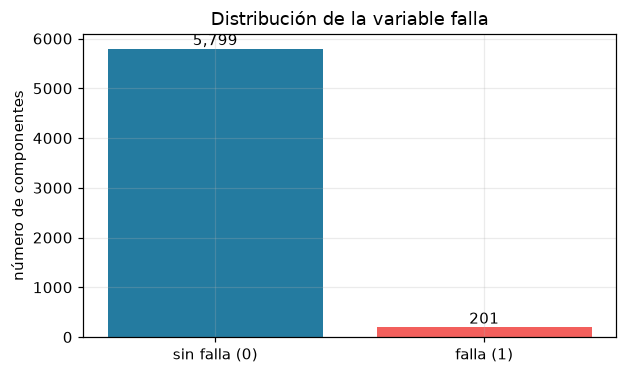

In [3]:
fig, ax = plt.subplots(figsize=(5.8, 3.5))
ax.bar(resumen_clases.index, resumen_clases["casos"], color=["#247BA0", "#F25F5C"])
ax.set_ylabel("número de componentes")
ax.set_title("Distribución de la variable falla")
for i, valor in enumerate(resumen_clases["casos"]):
    ax.text(i, valor + 70, f"{valor:,}", ha="center")
plt.tight_layout()
plt.show()

Hay 5,799 componentes sin falla y 201 con falla. La clase positiva representa 3.35 % del conjunto.
La partición estratificada conserva esa proporción: entrenamiento contiene 4,639 casos negativos y
161 positivos, mientras prueba contiene 1,160 negativos y 40 positivos.

## 3. Modelo base

In [4]:
def regresion_logistica(pesos=None):
    return LogisticRegression(
        class_weight=pesos,
        max_iter=2000,
        random_state=42,
    )


modelo_base = PipelineSklearn([
    ("escalador", StandardScaler()),
    ("modelo", regresion_logistica()),
])
modelo_base.fit(X_entrenamiento, y_entrenamiento)
prediccion_base = modelo_base.predict(X_prueba)

metricas_base = pd.Series({
    "exactitud": accuracy_score(y_prueba, prediccion_base),
    "MCC": matthews_corrcoef(y_prueba, prediccion_base),
    "kappa": cohen_kappa_score(y_prueba, prediccion_base),
})
metricas_base.round(4).to_frame("resultado")

,resultado
exactitud,0.9658
MCC,0.1687
kappa,0.1189


La exactitud de 0.9658 parece alta, pero casi coincide con el 96.67 % que se obtendría prediciendo
siempre la clase mayoritaria en prueba. MCC = 0.1687 y kappa = 0.1189 muestran que la separación real
entre fallas y casos normales es débil. Por eso la exactitud aislada no representa bien este problema.

## 4. Estrategias contra el desbalance

El escalamiento y el remuestreo se colocan dentro de cada pipeline. De esta forma, cada pliegue de
validación queda fuera del ajuste del escalador y de la generación o eliminación de observaciones.
Las cinco configuraciones usan la misma regresión logística.

In [5]:
configuraciones = {
    "Modelo base": PipelineSklearn([
        ("escalador", StandardScaler()),
        ("modelo", regresion_logistica()),
    ]),
    "Sobremuestreo": Pipeline([
        ("escalador", StandardScaler()),
        ("muestreo", RandomOverSampler(random_state=42)),
        ("modelo", regresion_logistica()),
    ]),
    "Submuestreo": Pipeline([
        ("escalador", StandardScaler()),
        ("muestreo", RandomUnderSampler(random_state=42)),
        ("modelo", regresion_logistica()),
    ]),
    "SMOTE": Pipeline([
        ("escalador", StandardScaler()),
        ("muestreo", SMOTE(random_state=42)),
        ("modelo", regresion_logistica()),
    ]),
    "Pesos balanceados": PipelineSklearn([
        ("escalador", StandardScaler()),
        ("modelo", regresion_logistica("balanced")),
    ]),
}

particiones = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metrica_mcc = make_scorer(matthews_corrcoef)
filas = []

for nombre, modelo in configuraciones.items():
    inicio = time.time()
    mcc_particiones = cross_val_score(
        modelo,
        X_entrenamiento,
        y_entrenamiento,
        cv=particiones,
        scoring=metrica_mcc,
        n_jobs=1,
    )
    modelo.fit(X_entrenamiento, y_entrenamiento)
    prediccion = modelo.predict(X_prueba)
    filas.append({
        "estrategia": nombre,
        "mcc_cv_media": mcc_particiones.mean(),
        "mcc_cv_desv": mcc_particiones.std(),
        "exactitud_prueba": accuracy_score(y_prueba, prediccion),
        "mcc_prueba": matthews_corrcoef(y_prueba, prediccion),
        "kappa_prueba": cohen_kappa_score(y_prueba, prediccion),
        "segundos": time.time() - inicio,
    })

comparacion = pd.DataFrame(filas).sort_values("mcc_cv_media", ascending=False).reset_index(drop=True)
comparacion.round(4)

,estrategia,mcc_cv_media,mcc_cv_desv,exactitud_prueba,mcc_prueba,kappa_prueba,segundos
0,Pesos balanceados,0.2283,0.0294,0.7842,0.2468,0.1484,0.0651
1,Submuestreo,0.2273,0.0289,0.7700,0.2453,0.1425,0.1337
2,Sobremuestreo,0.2240,0.0290,0.7850,0.2570,0.1543,0.0568
3,SMOTE,0.2231,0.0286,0.8000,0.2600,0.1620,0.0960
4,Modelo base,0.1402,0.0759,0.9658,0.1687,0.1189,0.0493


Los cuatro tratamientos mejoran el MCC de validación frente al modelo base. Los pesos balanceados
obtienen la media más alta, 0.2283, seguidos muy de cerca por el submuestreo con 0.2273. En prueba,
SMOTE alcanza el MCC más alto, 0.2600, pero esa diferencia no se usa para seleccionar el modelo porque
prueba debe conservarse como una verificación final.

Recomiendo los pesos balanceados. Su resultado en validación es el mejor, no elimina observaciones ni
crea casos sintéticos y mantiene un pipeline sencillo. La diferencia entre las cuatro estrategias es
pequeña, por lo que convendría repetir la comparación si hubiera más datos reales.

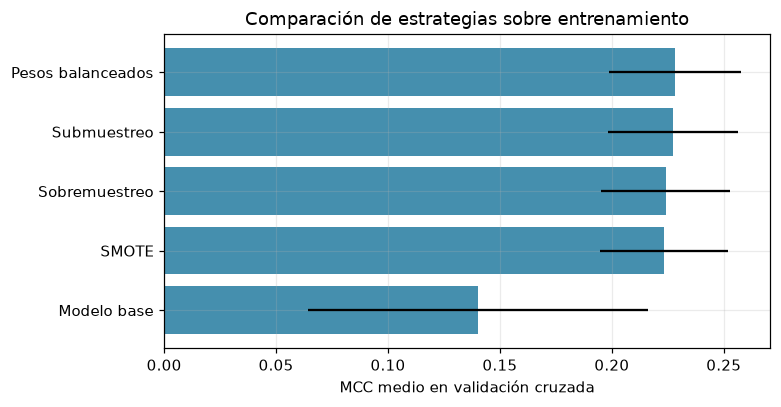

In [6]:
fig, ax = plt.subplots(figsize=(7.2, 3.8))
orden = comparacion.sort_values("mcc_cv_media")
ax.barh(orden["estrategia"], orden["mcc_cv_media"], xerr=orden["mcc_cv_desv"], color="#247BA0", alpha=0.85)
ax.set_xlabel("MCC medio en validación cruzada")
ax.set_title("Comparación de estrategias sobre entrenamiento")
plt.tight_layout()
plt.show()

## 5. Calibración de probabilidades

La calibración se ajusta con particiones internas del conjunto de entrenamiento. El conjunto de
prueba no interviene en ese proceso. Se usa el método sigmoide y se comparan las probabilidades sobre
la misma prueba reservada.

Brier antes:   0.1549
Brier después: 0.0287


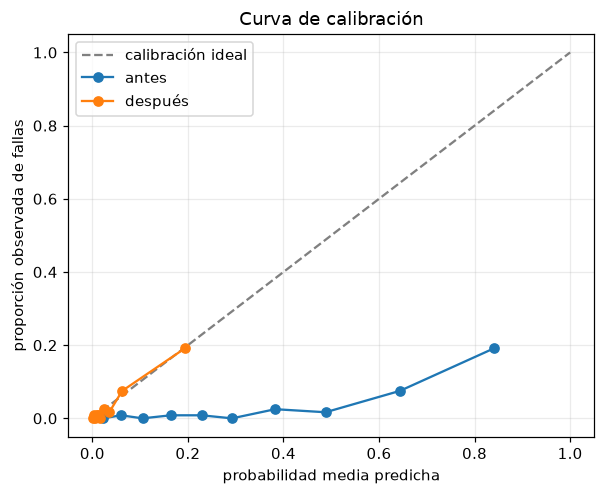

In [7]:
modelo_elegido = configuraciones["Pesos balanceados"]
modelo_elegido.fit(X_entrenamiento, y_entrenamiento)
probabilidad_antes = modelo_elegido.predict_proba(X_prueba)[:, 1]

modelo_calibrado = CalibratedClassifierCV(
    estimator=configuraciones["Pesos balanceados"],
    method="sigmoid",
    cv=particiones,
    n_jobs=1,
)
modelo_calibrado.fit(X_entrenamiento, y_entrenamiento)
probabilidad_despues = modelo_calibrado.predict_proba(X_prueba)[:, 1]

brier_antes = brier_score_loss(y_prueba, probabilidad_antes)
brier_despues = brier_score_loss(y_prueba, probabilidad_despues)

fraccion_antes, media_antes = calibration_curve(
    y_prueba, probabilidad_antes, n_bins=10, strategy="quantile"
)
fraccion_despues, media_despues = calibration_curve(
    y_prueba, probabilidad_despues, n_bins=10, strategy="quantile"
)

print(f"Brier antes:   {brier_antes:.4f}")
print(f"Brier después: {brier_despues:.4f}")

fig, ax = plt.subplots(figsize=(5.6, 4.6))
ax.plot([0, 1], [0, 1], "--", color="gray", label="calibración ideal")
ax.plot(media_antes, fraccion_antes, marker="o", label="antes")
ax.plot(media_despues, fraccion_despues, marker="o", label="después")
ax.set_xlabel("probabilidad media predicha")
ax.set_ylabel("proporción observada de fallas")
ax.set_title("Curva de calibración")
ax.legend()
plt.tight_layout()
plt.show()

El Brier score baja de 0.1549 a 0.0287. Antes de calibrar, la regresión con pesos de clase asigna
probabilidades demasiado altas porque modifica el costo de los errores. Después de la calibración,
la curva se acerca a la diagonal y las probabilidades representan mejor la frecuencia observada de
fallas. La calibración mejora la calidad probabilística, aunque no garantiza que el umbral 0.5 sea el
más adecuado para tomar una decisión industrial.

## 6. Conclusión

El modelo base conserva una exactitud alta porque la mayoría de los componentes no falla, pero MCC
y kappa revelan que su capacidad para separar ambas clases es limitada. Las cuatro estrategias
mejoran el MCC. Los pesos balanceados ofrecen el mejor promedio de validación y requieren menos
manipulación de los datos. La calibración sigmoide reduce de forma marcada el Brier score. Para una
aplicación real también fijaría el umbral de alerta con base en el costo de una falla no detectada y
el costo de una inspección innecesaria.